# var1: PCA factors (plots)
Needs `scenario_lab.factors.fit_pca(X, k)` returning `mean, V, explained`:
`mean` (6,), `V` (6, k) eigenvectors as columns sorted by eigenvalue, `explained` (k,) variance fractions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scenario_lab.data import load_curve
from scenario_lab.factors import fit_pca
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"  # undo IDE dark-theme recolouring

levels = load_curve("AAA")
changes = levels.diff().dropna()
mats = [1, 2, 5, 10, 20, 30]

## 1. Eigenvectors (factor shapes) of daily changes

explained: [0.79  0.15  0.037] cumulative: [0.79  0.94  0.977]
orthonormal: True


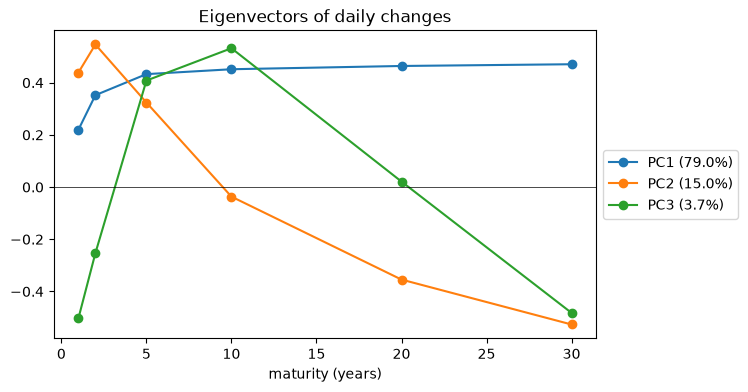

In [2]:
mean, V, explained = fit_pca(changes, k=3)
print("explained:", np.round(explained, 3), "cumulative:", np.round(np.cumsum(explained), 3))
print("orthonormal:", np.allclose(V.T @ V, np.eye(V.shape[1])))
fig, ax = plt.subplots(figsize=(7, 4))
for i, n in enumerate(["PC1", "PC2", "PC3"]):
    ax.plot(mats, V[:, i], marker="o", label=f"{n} ({explained[i]:.1%})")
ax.axhline(0, c="k", lw=0.5); ax.set(xlabel="maturity (years)", title="Eigenvectors of daily changes"); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

## 2. Factor time series (projection of the changes), cumulated so they look like levels

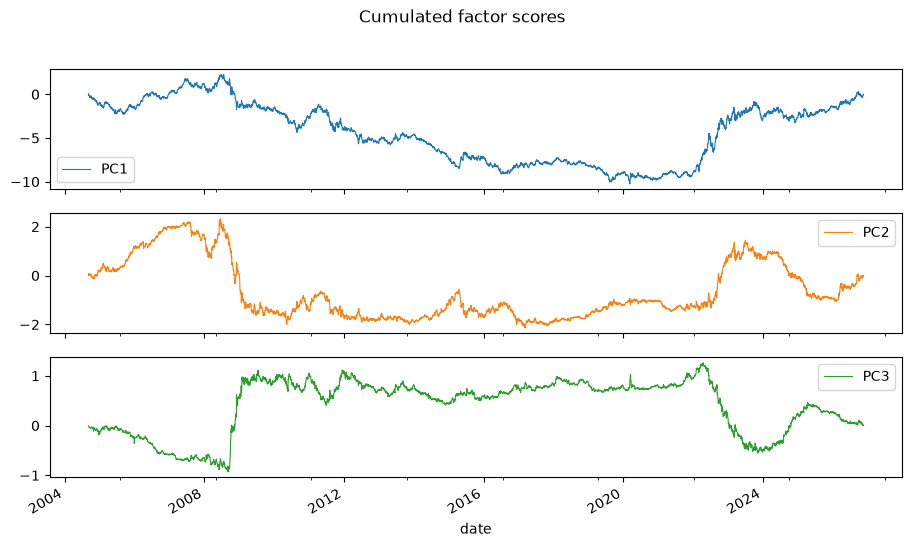

In [3]:
scores = pd.DataFrame((changes.values - mean) @ V, index=changes.index, columns=["PC1", "PC2", "PC3"])
scores.cumsum().plot(subplots=True, figsize=(11, 6), lw=0.8, title="Cumulated factor scores"); plt.show()

## 3. Reconstruction error by maturity (how much does dropping factors lose?)

In [4]:
err = {}
for k in (1, 2, 3):
    m, Vk, _ = fit_pca(changes, k=k)
    rec = (changes.values - m) @ Vk @ Vk.T + m
    err[k] = np.sqrt(((changes.values - rec) ** 2).mean(axis=0))
pd.DataFrame(err, index=changes.columns).rename(columns=lambda k: f"{k} factors").round(4).T

,1Y,2Y,5Y,10Y,20Y,30Y
1 factors,0.0205,0.0219,0.0159,0.0113,0.0151,0.0227
2 factors,0.0119,0.0072,0.0100,0.0112,0.0069,0.0107
3 factors,0.0071,0.0053,0.0064,0.0049,0.0069,0.0055


## 4. Same PCA on levels (open question: levels vs changes)

explained (levels): [0.9223 0.0744 0.0024]


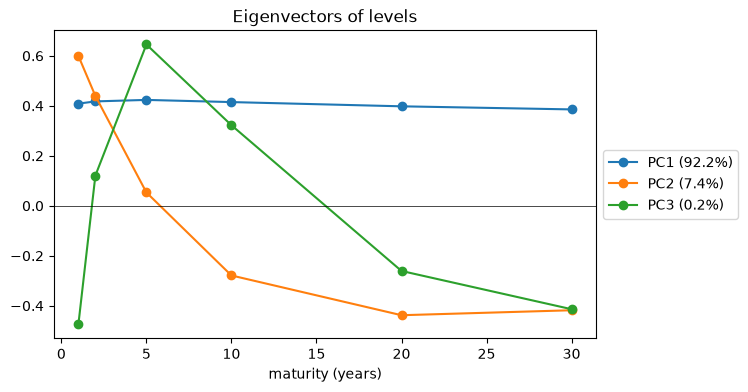

In [5]:
mean_l, V_l, expl_l = fit_pca(levels, k=3)
print("explained (levels):", np.round(expl_l, 4))
fig, ax = plt.subplots(figsize=(7, 4))
for i in range(3):
    ax.plot(mats, V_l[:, i], marker="o", label=f"PC{i+1} ({expl_l[i]:.1%})")
ax.axhline(0, c="k", lw=0.5); ax.set(xlabel="maturity (years)", title="Eigenvectors of levels"); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

## 5. Do the factor scores have memory? (decides the factor dynamics)
ACF of the scores (mean dynamics: OU/VAR) and of the squared scores (volatility clustering: constant vol or GARCH). Bars outside the band are significant; Ljung-Box p < 0.05 = autocorrelation present.

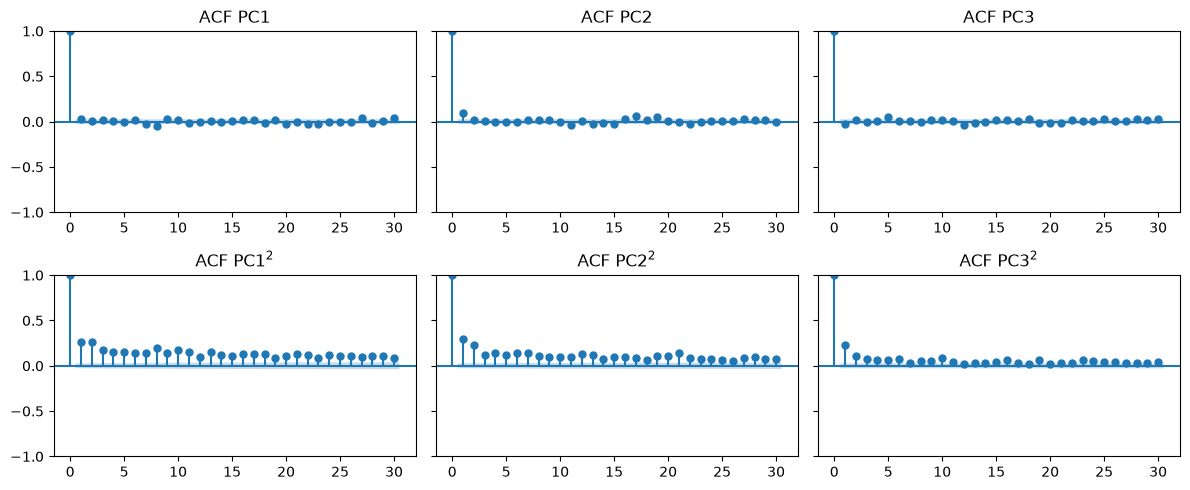

,"LB p (scores, 10 lags)","LB p (squared, 10 lags)"
PC1,0.0001,0.0
PC2,0.0000,0.0
PC3,0.0025,0.0


In [6]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharey=True)
for j, c in enumerate(scores.columns):
    plot_acf(scores[c], lags=30, ax=axes[0, j], title=f"ACF {c}")
    plot_acf(scores[c] ** 2, lags=30, ax=axes[1, j], title=f"ACF {c}$^2$")
plt.tight_layout(); plt.show()
pd.DataFrame({
    "LB p (scores, 10 lags)": [acorr_ljungbox(scores[c], lags=[10])["lb_pvalue"].iloc[0] for c in scores],
    "LB p (squared, 10 lags)": [acorr_ljungbox(scores[c] ** 2, lags=[10])["lb_pvalue"].iloc[0] for c in scores],
}, index=scores.columns).round(4)
